# Assignment Beta - Question 1
### SaafHawa: closed-source API vs self-hosted open-weight model
Ibrahim Johar Farooqi - 23K-0074 - BAI-7A

All model data was collected in **November 2026**. Every figure has a source id (S1, S2, ...) and the source list is at the end of the data cell.
All calculations below are done in this notebook. The report quotes the outputs.

In [1]:
import math, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## Parameters from my roll number

Roll number 23K-0074, digits 2, 3, 0, 0, 7, 4.

In [2]:
roll_digits = [2, 3, 0, 0, 7, 4]
R = 74
D = sum(roll_digits) % 10

Q = 1500 + 25 * R
N = 5 + (R % 4)
p = 0.04 + 0.01 * D
H = 4 + (R % 4)
B = 1200 + 10 * R
T = 10 - (R % 3)

print(f"R = {R}, D = ({' + '.join(map(str, roll_digits))}) mod 10 = {sum(roll_digits)} mod 10 = {D}")
print(f"Q = 1500 + 25*{R} = {Q}")
print(f"N = 5 + ({R} mod 4) = 5 + {R % 4} = {N}")
print(f"p = 0.04 + 0.01*{D} = {p:.2f}")
print(f"H = 4 + ({R} mod 4) = {H}")
print(f"B = 1200 + 10*{R} = ${B}")
print(f"T = 10 - ({R} mod 3) = 10 - {R % 3} = {T} s")

R = 74, D = (2 + 3 + 0 + 0 + 7 + 4) mod 10 = 16 mod 10 = 6
Q = 1500 + 25*74 = 3350
N = 5 + (74 mod 4) = 5 + 2 = 7
p = 0.04 + 0.01*6 = 0.10
H = 4 + (74 mod 4) = 6
B = 1200 + 10*74 = $1940
T = 10 - (74 mod 3) = 10 - 2 = 8 s


## Section 1: model data

Settings: every model in its non-reasoning / lowest reasoning setting. Where Artificial Analysis (AA) didn't publish the tool-use score
for that exact setting, the closest setting they did evaluate is used and labelled.

`reason_tok` = estimated hidden reasoning tokens per call for models that still think in their lowest setting.
None of the providers publish an average for these settings, so I estimate it from AA's measured time-to-first-token:
`(TTFT - 1.0 s) x output speed`, i.e. the extra time before the first visible token is assumed to be thinking at the model's normal decode speed.
1.0 s is roughly the TTFT of the non-reasoning models in the table. Models with no reasoning in the setting used get 0.

In [3]:
ACCESS = "November 2026"
models = [
  # ---------------- closed ----------------
  dict(name="GPT-6.1 Terra", provider="OpenAI", kind="closed", setting="reasoning_effort=none",
       params="not disclosed", ctx=1_050_000, max_out=128_000, src_ctx="S13",
       p_in=1.00, p_out=5.00, p_cache=0.05, cache_write_mult=1.25, cache_min=1024, cache_ttl_min=30, src_price="S13,S15",
       rpm=5000, tpm=1_000_000, rl_note="Build tier (entry paid tier)", src_rl="S13",
       ttft=2.13, tps=66, src_perf="S2",
       bench_gen="AA Intelligence Index v5.0.1 (none) = 31", bench_tool="AutomationBench-AA (low) = 56.2%", src_bench="S2,S38",
       tools="yes", json="yes", reasoning_opts="none, low, medium, high, xhigh, max", src_feat="S13",
       licence="proprietary / no", reason_tok=0),
  dict(name="GPT-6 Luna", provider="OpenAI", kind="closed", setting="reasoning_effort=none",
       params="not disclosed", ctx=1_050_000, max_out=128_000, src_ctx="S14",
       p_in=0.10, p_out=0.50, p_cache=0.01, cache_write_mult=1.25, cache_min=1024, cache_ttl_min=30, src_price="S14,S15",
       rpm=5000, tpm=2_000_000, rl_note="Build tier (entry paid tier)", src_rl="S14",
       ttft=1.68, tps=90, src_perf="S3",
       bench_gen="AA Intelligence Index v5.0.1 (none) = 9", bench_tool="AutomationBench-AA (low) = 12.0%", src_bench="S3,S4",
       tools="yes (Chat Completions needs effort=none)", json="yes", reasoning_opts="none, low, medium, high, xhigh, max", src_feat="S14",
       licence="proprietary / no", reason_tok=0),
  dict(name="Claude Haiku 5.5", provider="Anthropic", kind="closed", setting="effort=low (no non-thinking mode)",
       params="not disclosed", ctx=1_000_000, max_out=128_000, src_ctx="S16",
       p_in=0.10, p_out=0.50, p_cache=0.01, cache_write_mult=1.25, cache_min=512, cache_ttl_min=5, src_price="S16,S17",
       rpm=1000, tpm=2_000_000, otpm=400_000, rl_note="Start tier; 2M ITPM (uncached only) + 400k OTPM", src_rl="S18",
       ttft=7.41, tps=218, src_perf="S4",
       bench_gen="AA Intelligence Index v5.0.1 (low) = 19", bench_tool="AutomationBench-AA (low) = 22.9%", src_bench="S4",
       tools="yes", json="yes", reasoning_opts="adaptive thinking; effort low/medium(default)/high/xhigh/max", src_feat="S16,S41",
       licence="proprietary / no", reason_tok=None),
  dict(name="Claude Sonnet 5.5", provider="Anthropic", kind="closed", setting="effort=low (no non-thinking mode)",
       params="not disclosed", ctx=1_000_000, max_out=128_000, src_ctx="S16",
       p_in=2.00, p_out=10.00, p_cache=0.10, cache_write_mult=1.25, cache_min=512, cache_ttl_min=5, src_price="S5,S16,S17",
       rpm=1000, tpm=2_000_000, otpm=400_000, rl_note="Start tier; 2M ITPM (uncached only) + 400k OTPM", src_rl="S18",
       ttft=2.73, tps=137, src_perf="S5",
       bench_gen="AA Intelligence Index v5.0.1 (low) = 26", bench_tool="AutomationBench-AA (low) = 49.4%", src_bench="S5",
       tools="yes", json="yes", reasoning_opts="adaptive thinking; effort low/medium/high(default)/xhigh/max", src_feat="S16,S41",
       licence="proprietary / no", reason_tok=None),
  dict(name="Gemini 3.8 Flash", provider="Google", kind="closed", setting="thinking_level=low",
       params="not disclosed", ctx=1_000_000, max_out=None, src_ctx="S6",
       p_in=0.75, p_out=3.75, p_cache=0.075, cache_write_mult=1.0, cache_min=4096, cache_ttl_min=None, src_price="S20,S19",
       rpm=None, tpm=None, rl_note="not published (shown only in AI Studio)", src_rl="S22",
       ttft=4.40, tps=102, src_perf="S6",
       bench_gen="AA Intelligence Index v5.0.1 (low) = 23", bench_tool="AutomationBench-AA (low) = 36.5%", src_bench="S6",
       tools="yes", json="yes", reasoning_opts="low, medium, high", src_feat="S1,S21",
       licence="proprietary / no", reason_tok=None),
  dict(name="Gemini 3.5 Flash-Lite", provider="Google", kind="closed", setting="default thinking (lowest offered)",
       params="not disclosed", ctx=1_048_576, max_out=65_536, src_ctx="S21",
       p_in=0.30, p_out=2.50, p_cache=0.03, cache_write_mult=1.0, cache_min=4096, cache_ttl_min=None, src_price="S20,S19",
       rpm=None, tpm=None, rl_note="not published (shown only in AI Studio)", src_rl="S22",
       ttft=4.57, tps=297, src_perf="S7",
       bench_gen="AA Intelligence Index v5.0.1 = 12", bench_tool="AutomationBench-AA = 25.0%", src_bench="S7",
       tools="yes", json="yes", reasoning_opts="thinking supported (levels not listed)", src_feat="S21",
       licence="proprietary / no", reason_tok=None),
  dict(name="Grok 4.7", provider="xAI", kind="closed", setting="reasoning_effort=low",
       params="not disclosed", ctx=500_000, max_out=None, src_ctx="S23",
       p_in=2.00, p_out=6.00, p_cache=0.50, cache_write_mult=1.0, cache_min=0, cache_ttl_min=None, src_price="S23",
       rpm=9000, tpm=50_000_000, rl_note="150 req/s = 9,000 RPM; 50M TPM (tier not named)", src_rl="S23",
       ttft=11.75, tps=62, src_perf="S6",
       bench_gen="AA Intelligence Index v5.0.1 (low) = 31", bench_tool="AutomationBench-AA (low) = 56.7%", src_bench="S6",
       tools="yes", json="yes", reasoning_opts="low, medium, high (default), xhigh", src_feat="S23",
       licence="proprietary / no", reason_tok=None),
  # ---------------- open-weight ----------------
  dict(name="DeepSeek V4.1 Flash 1017", provider="DeepSeek", kind="open", setting="non-thinking",
       params="552B total / 16B active (MoE)", ctx=1_000_000, max_out=384_000, src_ctx="S8,S24,S25",
       p_in=0.30, p_out=1.20, p_cache=0.006, cache_write_mult=1.0, cache_min=0, cache_ttl_min=None, src_price="S24",
       host="DeepSeek API (peak-hour rate; off-peak is half)",
       rpm=None, tpm=None, rl_note="no RPM/TPM; 2,500 concurrent requests", src_rl="S24",
       ttft=1.34, tps=137, src_perf="S8",
       bench_gen="AA Intelligence Index v5.0.1 (non-reasoning) = 19", bench_tool="AutomationBench-AA (max) = 66.6%", src_bench="S8,S9",
       tools="yes", json="yes", reasoning_opts="thinking (default) / non-thinking", src_feat="S24",
       licence="MIT / yes", reason_tok=0),
  dict(name="Qwen3.8 27B", provider="Alibaba (Qwen)", kind="open", setting="thinking off",
       params="27B dense (hybrid Gated DeltaNet + attention, 3:1)", ctx=262_144, max_out=None, src_ctx="S39",
       p_in=0.425, p_out=2.55, p_cache=0.085, cache_write_mult=1.0, cache_min=0, cache_ttl_min=None, src_price="S26",
       host="OpenRouter",
       rpm=None, tpm=None, rl_note="not published", src_rl="S26",
       ttft=5.38, tps=43, src_perf="S1,S9",
       bench_gen="AA Intelligence Index v5.0.1 (non-reasoning) = 10", bench_tool="AutomationBench-AA (xhigh) = 48.2%", src_bench="S1,S9",
       tools="yes", json="yes (via tool/JSON schema)", reasoning_opts="thinking on (default) / off; reasoning_effort", src_feat="S39",
       licence="Apache-2.0 / yes", reason_tok=0),
  dict(name="Gemma 4 31B", provider="Google", kind="open", setting="thinking off",
       params="30.7B dense (sliding-window 1024 + global)", ctx=262_144, max_out=None, src_ctx="S33,S35",
       p_in=0.09, p_out=0.34, p_cache=None, cache_write_mult=1.0, cache_min=None, cache_ttl_min=None, src_price="S27",
       host="Deep Infra",
       rpm=None, tpm=None, rl_note="not published", src_rl="S27",
       ttft=3.84, tps=57, src_perf="S11",
       bench_gen="GPQA Diamond (vendor) = 84.3%", bench_tool="Tau2 avg of 3 (vendor) = 76.9%", src_bench="S33",
       tools="yes", json="yes", reasoning_opts="thinking on / off", src_feat="S35",
       licence="Apache 2.0 / yes", reason_tok=0),
  dict(name="Mistral Small 4", provider="Mistral AI", kind="open", setting="reasoning_effort=none",
       params="119B total / ~6.5B active (MoE, 128 experts, 4 active)", ctx=262_144, max_out=None, src_ctx="S32,S29",
       p_in=0.15, p_out=0.60, p_cache=0.015, cache_write_mult=1.0, cache_min=0, cache_ttl_min=None, src_price="S29,S12",
       host="Mistral AI",
       rpm=None, tpm=None, rl_note="not published per model", src_rl="S29",
       ttft=1.72, tps=118, src_perf="S12",
       bench_gen="AA Intelligence Index v5.0.1 (reasoning) = 4", bench_tool="AutomationBench-AA (reasoning) = 1.0%", src_bench="S12",
       tools="yes", json="yes", reasoning_opts="reasoning_effort none / high", src_feat="S32",
       licence="Apache 2.0 / yes", reason_tok=0),
  dict(name="gpt-oss-120b", provider="OpenAI", kind="open", setting="reasoning_effort=low (lowest)",
       params="117B total / 5.1B active (MoE)", ctx=131_072, max_out=131_072, src_ctx="S40",
       p_in=0.039, p_out=0.158, p_cache=None, cache_write_mult=1.0, cache_min=None, cache_ttl_min=None, src_price="S28",
       host="Geodd",
       rpm=None, tpm=None, rl_note="not published", src_rl="S28",
       ttft=1.27, tps=156, src_perf="S12",
       bench_gen="AA Intelligence Index v5.0.1 (high) = 4", bench_tool="AutomationBench-AA (high) = 0.2%", src_bench="S12",
       tools="yes", json="yes", reasoning_opts="low, medium, high", src_feat="S40",
       licence="Apache 2.0 / yes", reason_tok=None),
  dict(name="Mistral Medium 3.5", provider="Mistral AI", kind="open", setting="reasoning_effort=none",
       params="128B dense", ctx=262_144, max_out=262_144, src_ctx="S34",
       p_in=1.50, p_out=7.50, p_cache=0.15, cache_write_mult=1.0, cache_min=0, cache_ttl_min=None, src_price="S10,S29",
       host="Mistral AI",
       rpm=None, tpm=None, rl_note="not published per model", src_rl="S29",
       ttft=7.27, tps=144, src_perf="S10",
       bench_gen="AA Intelligence Index v5.0.1 (reasoning) = 5", bench_tool="AutomationBench-AA (reasoning) = 6.3%", src_bench="S10",
       tools="yes", json="yes", reasoning_opts="configurable reasoning effort per request", src_feat="S34",
       licence="Modified MIT / yes", reason_tok=0),
  dict(name="Ministral 3 14B", provider="Mistral AI", kind="open", setting="Instruct (no reasoning)",
       params="13.9B dense (13.5B LM + 0.4B vision)", ctx=262_144, max_out=None, src_ctx="S30",
       p_in=0.20, p_out=0.20, p_cache=None, cache_write_mult=1.0, cache_min=None, cache_ttl_min=None, src_price="S29",
       host="Mistral AI",
       rpm=None, tpm=None, rl_note="not published per model", src_rl="S29",
       ttft=2.67, tps=None, src_perf="S1",
       bench_gen="GPQA Diamond = 57.2%; Arena Hard (vendor) = 0.551", bench_tool="Tau2-Bench Telecom = 27.2%", src_bench="S30,S42",
       tools="yes", json="yes", reasoning_opts="none (separate Reasoning checkpoint)", src_feat="S30",
       licence="Apache 2.0 / yes", reason_tok=0),
]

SOURCES = {
 "S1": ("Artificial Analysis LLM leaderboard", "https://artificialanalysis.ai/en/leaderboards/models"),
 "S2": ("AA: GPT-6.1 Terra (Non-reasoning)", "https://artificialanalysis.ai/models/gpt-6-1-terra-non-reasoning"),
 "S3": ("AA: GPT-6 Luna (Non-reasoning)", "https://artificialanalysis.ai/models/gpt-6-luna-non-reasoning"),
 "S4": ("AA: Claude Haiku 5.5 (low) vs GPT-6 Luna (low)", "https://artificialanalysis.ai/models/comparisons/claude-haiku-5-5-low-vs-gpt-6-luna-low"),
 "S5": ("AA: Claude Haiku 5.5 vs Claude Sonnet 5.5 (low)", "https://artificialanalysis.ai/models/comparisons/claude-haiku-5-5-vs-claude-sonnet-5-5-low"),
 "S6": ("AA: Grok 4.7 (low) vs Gemini 3.8 Flash (low)", "https://artificialanalysis.ai/models/comparisons/grok-4-7-low-vs-gemini-3-8-flash-low"),
 "S7": ("AA: Qwen3.8 27B vs Gemini 3.5 Flash-Lite", "https://artificialanalysis.ai/models/comparisons/qwen3-8-27b-vs-gemini-3-5-flash-lite"),
 "S8": ("AA: DeepSeek V4.1 Flash 1017 (Non-reasoning)", "https://artificialanalysis.ai/ja/models/deepseek-v4-1-flash-1017-non-reasoning"),
 "S9": ("AA: DeepSeek V4.1 Flash 1017 vs Qwen3.8 27B", "https://artificialanalysis.ai/models/comparisons/deepseek-v4-1-flash-1017-vs-qwen3-8-27b"),
 "S10": ("AA: Mistral Medium 3.5 vs Gemma 4 31B (Non-reasoning)", "https://artificialanalysis.ai/models/comparisons/mistral-medium-3-5-vs-gemma-4-31b-non-reasoning"),
 "S11": ("AA: Gemma 4 31B (Non-reasoning)", "https://artificialanalysis.ai/models/gemma-4-31b-non-reasoning"),
 "S12": ("AA: Mistral Small 4 vs gpt-oss-120b", "https://artificialanalysis.ai/models/releases/comparisons/mistral-small-4-vs-gpt-oss-120b"),
 "S13": ("OpenAI model page: gpt-6.1-terra", "https://developers.openai.com/api/docs/models/gpt-6.1-terra"),
 "S14": ("OpenAI model page: gpt-6-luna", "https://developers.openai.com/api/docs/models/gpt-6-luna"),
 "S15": ("OpenAI prompt caching guide", "https://developers.openai.com/api/docs/guides/prompt-caching"),
 "S16": ("Anthropic: Claude Haiku 5.5 overview (+ model comparison)", "https://platform.claude.com/docs/en/models/haiku-5-5/overview"),
 "S17": ("Anthropic prompt caching", "https://platform.claude.com/docs/en/build-with-claude/prompt-caching"),
 "S18": ("Anthropic rate limits (DevelopersDigest copy of platform.claude.com docs)", "https://www.developersdigest.tech/rate-limits/anthropic"),
 "S19": ("Google Gemini API context caching", "https://ai.google.dev/gemini-api/docs/caching"),
 "S20": ("Gemini API pricing (Morph summary of Google pricing page)", "https://www.morphllm.com/gemini-api-pricing"),
 "S21": ("Google: Gemini 3.5 Flash-Lite model page", "https://ai.google.dev/gemini-api/docs/models/gemini-3.5-flash-lite"),
 "S22": ("Gemini rate limits (DevelopersDigest copy of Google docs)", "https://www.developersdigest.tech/rate-limits/google"),
 "S23": ("xAI docs: Grok 4.7", "https://docs.x.ai/docs/models/grok-4.7"),
 "S24": ("DeepSeek API models & pricing", "https://api-docs.deepseek.com/quick_start/pricing"),
 "S25": ("OpenRouter: DeepSeek V4.1 Flash 1017", "https://openrouter.ai/deepseek/deepseek-v4.1-flash-1017/providers"),
 "S26": ("LLM Reference: Qwen3.8-27B providers", "https://www.llmreference.com/model/qwen3.8-27b/providers"),
 "S27": ("ComputePrices: Gemma 4 31B providers", "https://computeprices.com/providers/openrouter/models/gemma-4-31b-it"),
 "S28": ("ComputePrices: gpt-oss-120b providers", "https://computeprices.com/providers/openrouter/models/gpt-oss-120b"),
 "S29": ("OpenRouter: Mistral provider page", "https://openrouter.ai/provider/mistral"),
 "S30": ("Hugging Face: Ministral-3-14B-Instruct-2512 model card", "https://huggingface.co/mistralai/Ministral-3-14B-Instruct-2512"),
 "S31": ("Hugging Face: Ministral-3-14B-Instruct-2512 config.json", "https://huggingface.co/mistralai/Ministral-3-14B-Instruct-2512/blob/main/config.json"),
 "S32": ("Hugging Face: Mistral-Small-4-119B-2603 card", "https://huggingface.co/unsloth/Mistral-Small-4-119B-2603"),
 "S33": ("Google: Gemma 4 model card", "https://ai.google.dev/gemma/docs/core/model_card_4"),
 "S34": ("OpenRouter: Mistral Medium 3.5", "https://openrouter.ai/mistralai/mistral-medium-3-5/providers"),
 "S35": ("OpenRouter: Gemma 4 31B", "https://openrouter.ai/google/gemma-4-31b-it/providers"),
 "S36": ("RunPod GPU pricing", "https://www.runpod.io/pricing"),
 "S38": ("AA: GPT-6.1 Terra (low) vs Claude Opus 5.5", "https://artificialanalysis.ai/models/comparisons/gpt-6-1-terra-low-vs-claude-opus-5-5"),
 "S39": ("Hugging Face: Qwen3.8-27B card (Unsloth mirror of Qwen card)", "https://huggingface.co/unsloth/Qwen3.8-27B"),
 "S40": ("OpenAI model page: gpt-oss-120b", "https://developers.openai.com/api/docs/models/gpt-oss-120b"),
 "S41": ("AA leaderboard effort variants for Claude 5.5 (low/medium/high/xhigh/max)", "https://artificialanalysis.ai/en/leaderboards/models"),
 "S42": ("BenchmarkList: Ministral 3 14B scores", "https://benchmarklist.com/models/ministral-3-14b/"),
}

for m in models:
    if m["reason_tok"] is None:
        m["reason_tok"] = round(max(0.0, m["ttft"] - 1.0) * m["tps"])
df = pd.DataFrame(models)
print(len(df[df.kind == "closed"]), "closed from", df[df.kind == "closed"].provider.nunique(), "providers |",
      len(df[df.kind == "open"]), "open from", df[df.kind == "open"].provider.nunique(), "providers")
df[["name", "setting", "ttft", "tps", "reason_tok"]]

7 closed from 4 providers | 7 open from 5 providers


,name,setting,ttft,tps,reason_tok
0,GPT-6.1 Terra,reasoning_effort=none,2.13,66.0,0
1,GPT-6 Luna,reasoning_effort=none,1.68,90.0,0
2,Claude Haiku 5.5,effort=low (no non-thinking mode),7.41,218.0,1397
3,Claude Sonnet 5.5,effort=low (no non-thinking mode),2.73,137.0,237
4,Gemini 3.8 Flash,thinking_level=low,4.40,102.0,347
5,Gemini 3.5 Flash-Lite,default thinking (lowest offered),4.57,297.0,1060
6,Grok 4.7,reasoning_effort=low,11.75,62.0,666
7,DeepSeek V4.1 Flash 1017,non-thinking,1.34,137.0,0
8,Qwen3.8 27B,thinking off,5.38,43.0,0
9,Gemma 4 31B,thinking off,3.84,57.0,0


## Section 2.1: token volume per query and per month

Call k has input 2000 + 800(k-1) tokens. Calls 1..N-1 output 350 and each makes one tool call; call N outputs 600.
Calls 1..N-1 are retried once with probability p (same input, same output).

In [4]:
k = np.arange(1, N + 1)
inp = 2000 + 800 * (k - 1)
out = np.where(k < N, 350, 600)
retry_p = np.where(k < N, p, 0.0)

calls = pd.DataFrame({"call k": k, "input": inp, "output": out, "P(retry)": retry_p,
                      "E[input]": inp * (1 + retry_p), "E[output]": out * (1 + retry_p)})
print(calls.to_string(index=False))

E_in = calls["E[input]"].sum()
E_out = calls["E[output]"].sum()
E_calls = N + p * (N - 1)
print(f"\nfirst-attempt input  = {inp.sum():,}   + retries {p} x {inp[:-1].sum():,} = {E_in:,.0f} tokens/query")
print(f"first-attempt output = {out.sum():,}   + retries {p} x {out[:-1].sum():,} = {E_out:,.0f} tokens/query")
print(f"expected LLM requests per query = {N} + {p} x {N - 1} = {E_calls:.2f}")

 call k  input  output  P(retry)  E[input]  E[output]
      1   2000     350       0.1    2200.0      385.0
      2   2800     350       0.1    3080.0      385.0
      3   3600     350       0.1    3960.0      385.0
      4   4400     350       0.1    4840.0      385.0
      5   5200     350       0.1    5720.0      385.0
      6   6000     350       0.1    6600.0      385.0
      7   6800     600       0.0    6800.0      600.0

first-attempt input  = 30,800   + retries 0.1 x 24,000 = 33,200 tokens/query
first-attempt output = 2,700   + retries 0.1 x 2,100 = 2,910 tokens/query
expected LLM requests per query = 7 + 0.1 x 6 = 7.60


In [5]:
normal_days = 30 - H
q_month = normal_days * Q + H * 5 * Q
print(f"monthly queries = {normal_days} x {Q:,} + {H} x 5 x {Q:,} = {q_month:,}")

M_in = q_month * E_in
M_out = q_month * E_out
M_calls = q_month * E_calls
print(f"monthly input  = {q_month:,} x {E_in:,.0f} = {M_in:,.0f}  ({M_in / 1e9:.3f} B)")
print(f"monthly output = {q_month:,} x {E_out:,.0f} = {M_out:,.0f}  ({M_out / 1e6:.1f} M)")
print(f"monthly LLM requests = {M_calls:,.0f}")

CACHE_PREFIX = 1500
M_cacheable = M_calls * CACHE_PREFIX
print(f"cacheable prefix tokens/month = {M_calls:,.0f} x {CACHE_PREFIX} = {M_cacheable:,.0f} ({M_cacheable / M_in:.1%} of input)")

monthly queries = 24 x 3,350 + 6 x 5 x 3,350 = 180,900
monthly input  = 180,900 x 33,200 = 6,005,880,000  (6.006 B)
monthly output = 180,900 x 2,910 = 526,419,000  (526.4 M)
monthly LLM requests = 1,374,840
cacheable prefix tokens/month = 1,374,840 x 1500 = 2,062,260,000 (34.3% of input)


## Section 2.2: monthly API cost, with and without caching

- Without caching: `input x p_in + (output + reasoning) x p_out`
- With caching, if the 1,500-token prefix is at least the provider's minimum and a cached price exists:
  every call's first 1,500 tokens are billed at the cached-read price, except cache **writes**.
- The prefix (system prompt + tool schemas) is identical for every user, and at ~~18 calls/minute on a normal day it never goes cold,
  so it only gets re-written when the cache lifetime runs out: `writes/month = 30 x 24 x 60 / TTL`.
  A write is billed at `write multiplier x p_in`. Providers with no write premium are billed normally on a miss, so I ignore their writes.
- Gemini's implicit-cache minimum is 4,096 tokens, so 1,500 tokens is too short: no caching. Gemma (Deep Infra), gpt-oss (Geodd) and Ministral (Mistral) list no cached price: no caching.

In [6]:
def monthly_cost(m, cached):
    reason = m["reason_tok"] * M_calls
    out_cost = (M_out + reason) * m["p_out"] / 1e6
    if not cached:
        return M_in * m["p_in"] / 1e6 + out_cost, 0.0
    write_tok = 0.0
    if m["cache_ttl_min"] and m["cache_write_mult"] > 1:
        write_tok = (30 * 24 * 60 / m["cache_ttl_min"]) * CACHE_PREFIX
    read_tok = M_cacheable - write_tok
    in_cost = ((M_in - M_cacheable) * m["p_in"] + read_tok * m["p_cache"] + write_tok * m["p_in"] * m["cache_write_mult"]) / 1e6
    return in_cost + out_cost, write_tok

def can_cache(m):
    return m["p_cache"] is not None and m["cache_min"] is not None and m["cache_min"] <= CACHE_PREFIX

rows = []
for m in models:
    c0, _ = monthly_cost(m, False)
    if can_cache(m):
        c1, wt = monthly_cost(m, True)
    else:
        c1, wt = c0, 0.0
    rows.append({"model": m["name"], "kind": m["kind"], "p_in": m["p_in"], "p_out": m["p_out"], "p_cache": m["p_cache"],
                 "reason tok/call": m["reason_tok"], "cache?": "yes" if can_cache(m) else "no",
                 "cache writes (tok)": wt, "no cache $": c0, "with cache $": c1,
                 "within B (no cache)": c0 <= B, "within B (cache)": c1 <= B})
cost = pd.DataFrame(rows)
cost.round(2)

,model,kind,p_in,p_out,p_cache,reason tok/call,cache?,cache writes (tok),no cache $,with cache $,within B (no cache),within B (cache)
0,GPT-6.1 Terra,closed,1.00,5.00,0.05,0,yes,2160000.0,8637.98,6681.42,False,False
1,GPT-6 Luna,closed,0.10,0.50,0.01,0,yes,2160000.0,863.80,678.44,True,True
2,Claude Haiku 5.5,closed,0.10,0.50,0.01,1397,yes,12960000.0,1824.12,1640.01,True,True
3,Claude Sonnet 5.5,closed,2.00,10.00,0.10,237,yes,12960000.0,20534.32,16647.13,False,False
4,Gemini 3.8 Flash,closed,0.75,3.75,0.08,347,no,0.0,8267.49,8267.49,False,False
5,Gemini 3.5 Flash-Lite,closed,0.30,2.50,0.03,1060,no,0.0,6761.14,6761.14,False,False
6,Grok 4.7,closed,2.00,6.00,0.50,666,yes,0.0,20664.13,17570.74,False,False
7,DeepSeek V4.1 Flash 1017,open,0.30,1.20,0.01,0,yes,0.0,2433.47,1827.16,False,True
8,Qwen3.8 27B,open,0.42,2.55,0.08,0,yes,0.0,3894.87,3193.70,False,False
9,Gemma 4 31B,open,0.09,0.34,NaN,0,no,0.0,719.51,719.51,True,True


In [7]:
# worked example for one model so the arithmetic can be followed in the report
m = next(x for x in models if x["name"] == "Claude Haiku 5.5")
reason = m["reason_tok"] * M_calls
wt = (30 * 24 * 60 / m["cache_ttl_min"]) * CACHE_PREFIX
print(f"Haiku reasoning tokens/month = {m['reason_tok']} x {M_calls:,.0f} = {reason:,.0f}")
print(f"no cache: {M_in:,.0f} x 0.10/1e6 + ({M_out:,.0f} + {reason:,.0f}) x 0.50/1e6 = ${M_in * 0.1 / 1e6:,.2f} + ${(M_out + reason) * 0.5 / 1e6:,.2f}")
print(f"cache writes = 30*24*60/5 = {30 * 24 * 60 / 5:,.0f} writes x 1500 = {wt:,.0f} tokens at 1.25 x $0.10")
print(f"cached reads = {M_cacheable - wt:,.0f} tokens at $0.01")

Haiku reasoning tokens/month = 1397 x 1,374,840 = 1,920,651,480
no cache: 6,005,880,000 x 0.10/1e6 + (526,419,000 + 1,920,651,480) x 0.50/1e6 = $600.59 + $1,223.54
cache writes = 30*24*60/5 = 8,640 writes x 1500 = 12,960,000 tokens at 1.25 x $0.10
cached reads = 2,049,300,000 tokens at $0.01


In [8]:
# sensitivity: worst case where every query's first call writes the cache (no sharing across users)
rows = []
for m in models:
    if not can_cache(m) or m["cache_write_mult"] <= 1:
        continue
    reason = m["reason_tok"] * M_calls
    write_tok = q_month * CACHE_PREFIX
    read_tok = M_cacheable - write_tok
    c = ((M_in - M_cacheable) * m["p_in"] + read_tok * m["p_cache"] + write_tok * m["p_in"] * m["cache_write_mult"] + (M_out + reason) * m["p_out"]) / 1e6
    rows.append({"model": m["name"], "with cache (shared prefix)": cost.set_index("model").loc[m["name"], "with cache $"], "with cache (write every query)": c})
pd.DataFrame(rows).round(2)

,model,with cache (shared prefix),with cache (write every query)
0,GPT-6.1 Terra,6681.42,7004.45
1,GPT-6 Luna,678.44,709.40
2,Claude Haiku 5.5,1640.01,1669.73
3,Claude Sonnet 5.5,16647.13,17267.27


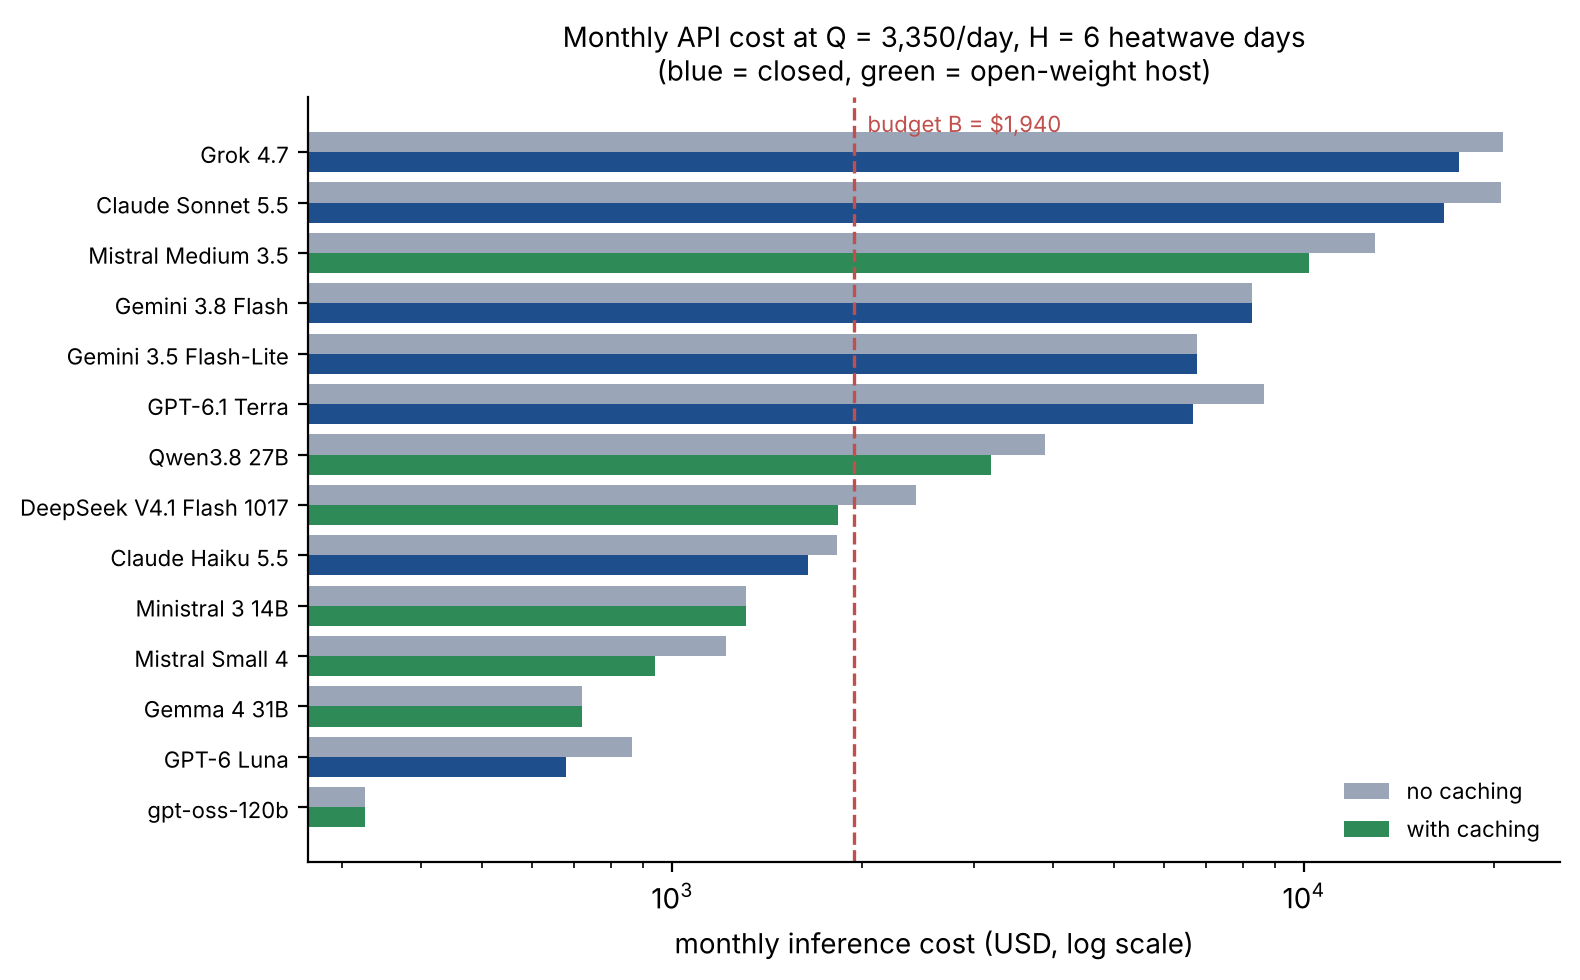

In [9]:
plot = cost.sort_values("with cache $")
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(plot))
ax.barh(y + 0.2, plot["no cache $"], 0.4, color="#9aa5b8", label="no caching")
ax.barh(y - 0.2, plot["with cache $"], 0.4, color=["#1F4E8C" if k == "closed" else "#2E8B57" for k in plot["kind"]], label="with caching")
ax.axvline(B, color="#C0504D", ls="--", lw=1.2)
ax.text(B * 1.05, len(plot) - 0.6, f"budget B = ${B:,}", color="#C0504D", fontsize=8)
ax.set_yticks(y, plot["model"], fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("monthly inference cost (USD, log scale)")
ax.set_title("Monthly API cost at Q = 3,350/day, H = 6 heatwave days\n(blue = closed, green = open-weight host)", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("q1_monthly_cost.png", dpi=200); plt.show()

## Section 2.3: peak load in the heatwave window

In [10]:
peak_day = 5 * Q
peak_window = 0.35 * peak_day
qpm = peak_window / 120
rpm_peak = qpm * E_calls
in_tpm = qpm * E_in
out_tpm = qpm * E_out
uncached_in_tpm = in_tpm - qpm * E_calls * CACHE_PREFIX
print(f"heatwave day = 5 x {Q:,} = {peak_day:,} queries; 35% in 12:00-14:00 = {peak_window:,.1f}")
print(f"peak queries/min = {peak_window:,.1f} / 120 = {qpm:.2f}  ({qpm / 60:.3f} per second)")
print(f"peak LLM requests/min = {qpm:.2f} x {E_calls:.2f} = {rpm_peak:,.0f} RPM")
print(f"peak input TPM  = {qpm:.2f} x {E_in:,.0f} = {in_tpm:,.0f}")
print(f"peak output TPM = {qpm:.2f} x {E_out:,.0f} = {out_tpm:,.0f}  (before reasoning tokens)")
print(f"peak total TPM  = {in_tpm + out_tpm:,.0f}")
print(f"uncached input TPM (if prefix is cached) = {uncached_in_tpm:,.0f}")

heatwave day = 5 x 3,350 = 16,750 queries; 35% in 12:00-14:00 = 5,862.5
peak queries/min = 5,862.5 / 120 = 48.85  (0.814 per second)
peak LLM requests/min = 48.85 x 7.60 = 371 RPM
peak input TPM  = 48.85 x 33,200 = 1,621,958
peak output TPM = 48.85 x 2,910 = 142,166  (before reasoning tokens)
peak total TPM  = 1,764,124
uncached input TPM (if prefix is cached) = 1,065,021


In [11]:
rl = []
for m in models:
    o_tpm = out_tpm + qpm * E_calls * m["reason_tok"]
    tot = in_tpm + o_tpm
    if m["rpm"] is None:
        verdict = "limits not published"
    elif m.get("otpm"):
        ok = rpm_peak <= m["rpm"] and uncached_in_tpm <= m["tpm"] and o_tpm <= m["otpm"]
        verdict = "OK" if ok else "EXCEEDED (" + ", ".join(x for x, bad in [("RPM", rpm_peak > m["rpm"]), ("ITPM", uncached_in_tpm > m["tpm"]), ("OTPM", o_tpm > m["otpm"])] if bad) + ")"
    else:
        ok = rpm_peak <= m["rpm"] and tot <= m["tpm"]
        verdict = "OK" if ok else "EXCEEDED (" + ", ".join(x for x, bad in [("RPM", rpm_peak > m["rpm"]), ("TPM", tot > m["tpm"])] if bad) + ")"
    rl.append({"model": m["name"], "limit": m["rl_note"], "RPM limit": m["rpm"], "TPM limit": m["tpm"],
               "peak RPM": round(rpm_peak), "peak total TPM": round(tot), "peak output TPM": round(o_tpm), "verdict": verdict})
rl_df = pd.DataFrame(rl)
rl_df

,model,limit,RPM limit,TPM limit,peak RPM,peak total TPM,peak output TPM,verdict
0,GPT-6.1 Terra,Build tier (entry paid tier),5000.0,1000000.0,371,1764124,142166,EXCEEDED (TPM)
1,GPT-6 Luna,Build tier (entry paid tier),5000.0,2000000.0,371,1764124,142166,OK
2,Claude Haiku 5.5,Start tier; 2M ITPM (uncached only) + 400k OTPM,1000.0,2000000.0,371,2282818,660860,EXCEEDED (OTPM)
3,Claude Sonnet 5.5,Start tier; 2M ITPM (uncached only) + 400k OTPM,1000.0,2000000.0,371,1852120,230162,OK
4,Gemini 3.8 Flash,not published (shown only in AI Studio),NaN,NaN,371,1892962,271004,limits not published
5,Gemini 3.5 Flash-Lite,not published (shown only in AI Studio),NaN,NaN,371,2157693,535735,limits not published
6,Grok 4.7,"150 req/s = 9,000 RPM; 50M TPM (tier not named)",9000.0,50000000.0,371,2011404,389446,OK
7,DeepSeek V4.1 Flash 1017,"no RPM/TPM; 2,500 concurrent requests",NaN,NaN,371,1764124,142166,limits not published
8,Qwen3.8 27B,not published,NaN,NaN,371,1764124,142166,limits not published
9,Gemma 4 31B,not published,NaN,NaN,371,1764124,142166,limits not published


## Section 2.6: latency budget

Done before 2.4/2.5 because the self-hosting part needs the session length.

**Tool delay.** Median of every measurement in `tool_latency_log.csv` (OpenAQ + Open-Meteo calls over two days, plus local heat-index and KB timings).

**Per-call latency model** for call k with input $I_k$ and output $O_k$:

$$t_k = \underbrace{\text{TTFT} + \frac{I_k - 1000}{\text{prefill rate}}}_{\text{time to first token}} + \frac{O_k}{\text{output speed}}$$

AA measures TTFT on roughly 1,000-token prompts, and our calls are 2,000-6,800 tokens, so each call's TTFT grows with its context.
I assume a prefill rate of 5,000 tokens/s for hosted APIs (conservative; checked with 2,500 and 10,000 below).
For thinking models AA's TTFT already includes the hidden thinking, so reasoning isn't counted twice.

Query latency = sum of the N calls + (N-1) tool delays + expected retries ($p \times t_k$ for k < N).

In [12]:
LOG = "tool_latency_log.csv"
log = pd.read_csv(LOG) if os.path.exists(LOG) else None
if log is not None:
    log = log[log["status"].astype(str) != "error"].copy()
    log["latency_ms"] = log["latency_ms"].astype(float)
    per_tool = log.groupby("tool")["latency_ms"].agg(["count", "median", "mean", "min", "max"])
    per_tool["days"] = log.groupby("tool")["day"].nunique()
    print(per_tool.round(3))
    TOOL_DELAY = log["latency_ms"].median() / 1000
    API_ONLY = log[log["tool"].isin(["air_quality_openaq", "weather_openmeteo"])]["latency_ms"].median() / 1000
    print(f"\npooled median of all {len(log)} measurements = {TOOL_DELAY * 1000:.1f} ms  <- used as the delay per tool call (as the brief says)")
    print(f"median of the two network APIs only        = {API_ONLY * 1000:.1f} ms  (sensitivity check)")
else:
    TOOL_DELAY = API_ONLY = None
    print("tool_latency_log.csv not found yet - run saafhawa_latency_logger.py on two days first")

                    count   median     mean      min       max  days
tool                                                                
air_quality_openaq     24  800.854  834.807  739.814  1183.623     2
heat_index_local       24    0.000    0.000    0.000     0.001     2
kb_lookup_local        24    0.072    0.077    0.066     0.104     2
weather_openmeteo      24  523.101  537.021  482.470   953.361     2

pooled median of all 96 measurements = 241.3 ms  <- used as the delay per tool call (as the brief says)
median of the two network APIs only        = 745.1 ms  (sensitivity check)


In [13]:
PREFILL = 5000
TTFT_REF = 1000

def query_latency(m, n_calls, d_tool, prefill=PREFILL, stream_final=False):
    kk = np.arange(1, n_calls + 1)
    I = 2000 + 800 * (kk - 1)
    O = np.where(kk < n_calls, 350, 600)
    ttft = m["ttft"] + np.maximum(I - TTFT_REF, 0) / prefill
    t = ttft + O / m["tps"]
    if stream_final:
        t[-1] = ttft[-1]
    retry = p * t[:-1].sum()
    tools = (n_calls - 1) * d_tool
    return {"LLM time": t.sum(), "tool time": tools, "retry time": retry, "total": t.sum() + tools + retry,
            "per call": np.round(t, 2)}

CANDIDATES = ["DeepSeek V4.1 Flash 1017", "Claude Haiku 5.5"]
cand = {m["name"]: m for m in models if m["name"] in CANDIDATES}
d = TOOL_DELAY if TOOL_DELAY is not None else float("nan")
lat_rows = []
for name, m in cand.items():
    r = query_latency(m, N, d)
    print(f"{name}: per-call seconds {r['per call']}")
    lat_rows.append({"model": name, "design": f"baseline ({N} sequential calls)", **{k: v for k, v in r.items() if k != "per call"}})
pd.DataFrame(lat_rows).round(2)

Claude Haiku 5.5: per-call seconds [ 9.22  9.38  9.54  9.7   9.86 10.02 11.32]
DeepSeek V4.1 Flash 1017: per-call seconds [4.09 4.25 4.41 4.57 4.73 4.89 6.88]


,model,design,LLM time,tool time,retry time,total
0,Claude Haiku 5.5,baseline (7 sequential calls),69.02,1.45,5.77,76.23
1,DeepSeek V4.1 Flash 1017,baseline (7 sequential calls),33.85,1.45,2.70,37.99


### Architectural change: parallel tool calls

The six tool steps aren't all dependent on each other. Area/time/person extraction, the air-quality call, the weather call and the KB lookup
only need the user's message, so the model can emit them **in one turn as parallel tool calls** (OpenAI, Anthropic and DeepSeek all support
several tool calls per turn). The heat index needs the weather result, but it is a deterministic formula, so the tool layer computes it
straight after the weather call without another LLM turn.

That turns 7 sequential LLM calls into 3: (1) understand the message and fire all tools in parallel, (2) read the results and check whether anything is
missing, (3) write the answer. A parallel round takes as long as its slowest tool, so it still counts as one tool delay.

In [14]:
N_PAR = 3
for name, m in cand.items():
    r = query_latency(m, N_PAR, d)
    lat_rows.append({"model": name, "design": "parallel tools (3 LLM calls)", **{k: v for k, v in r.items() if k != "per call"}})
    r = query_latency(m, N_PAR, d, stream_final=True)
    lat_rows.append({"model": name, "design": "parallel + stream final answer (time to first word)", **{k: v for k, v in r.items() if k != "per call"}})
lat = pd.DataFrame(lat_rows)
lat["meets T"] = lat["total"] <= T
lat.round(2)

,model,design,LLM time,tool time,retry time,total,meets T
0,Claude Haiku 5.5,baseline (7 sequential calls),69.02,1.45,5.77,76.23,False
1,DeepSeek V4.1 Flash 1017,baseline (7 sequential calls),33.85,1.45,2.70,37.99,False
2,Claude Haiku 5.5,parallel tools (3 LLM calls),29.27,0.48,1.86,31.61,False
3,Claude Haiku 5.5,parallel + stream final answer (time to first ...,26.52,0.48,1.86,28.86,False
4,DeepSeek V4.1 Flash 1017,parallel tools (3 LLM calls),14.59,0.48,0.83,15.91,False
5,DeepSeek V4.1 Flash 1017,parallel + stream final answer (time to first ...,10.21,0.48,0.83,11.53,False


In [15]:
sens = []
for pf in [2500, 5000, 10000]:
    for name, m in cand.items():
        sens.append({"prefill tok/s": pf, "model": name,
                     "baseline": query_latency(m, N, d, pf)["total"], "parallel": query_latency(m, N_PAR, d, pf)["total"]})
if API_ONLY is not None:
    for name, m in cand.items():
        sens.append({"prefill tok/s": "5000, API-only tool median", "model": name,
                     "baseline": query_latency(m, N, API_ONLY)["total"], "parallel": query_latency(m, N_PAR, API_ONLY)["total"]})
pd.DataFrame(sens).round(2)

,prefill tok/s,model,baseline,parallel
0,2500,Claude Haiku 5.5,81.35,32.75
1,2500,DeepSeek V4.1 Flash 1017,43.11,17.04
2,5000,Claude Haiku 5.5,76.23,31.61
3,5000,DeepSeek V4.1 Flash 1017,37.99,15.91
4,10000,Claude Haiku 5.5,73.67,31.05
5,10000,DeepSeek V4.1 Flash 1017,35.43,15.34
6,"5000, API-only tool median",Claude Haiku 5.5,79.26,32.62
7,"5000, API-only tool median",DeepSeek V4.1 Flash 1017,41.02,16.91


## Section 2.4: self-hosting memory (Ministral 3 14B Instruct 2512)

Chosen because it uses standard **grouped-query full attention** (no sliding window, no linear/latent attention), so the KV formula applies as given.
Values from `config.json` (text_config) on Hugging Face [S31], screenshot in the report:

In [16]:
layers, kv_heads, head_dim = 40, 8, 128
hidden, n_heads = 5120, 32
params_total = 13.9e9      # 13.5B language model + 0.4B vision encoder [S30]
print("head_dim listed:", head_dim, "| hidden/heads check:", hidden // n_heads)

for name, bpp in [("FP16", 2), ("8-bit", 1), ("4-bit", 0.5)]:
    print(f"weights {name:5s}: {params_total / 1e9:.1f}e9 x {bpp} B = {params_total * bpp / 1e9:.2f} GB")

head_dim listed: 128 | hidden/heads check: 160
weights FP16 : 13.9e9 x 2 B = 27.80 GB
weights 8-bit: 13.9e9 x 1 B = 13.90 GB
weights 4-bit: 13.9e9 x 0.5 B = 6.95 GB


In [17]:
seq_len = int(inp.max() + out[-1])   # longest context in the loop: last call's input + its 600 output tokens
kv_bytes = 2 * layers * kv_heads * head_dim * seq_len * 2
print(f"longest sequence = {inp.max():,} input + {out[-1]} output = {seq_len:,} tokens")
print(f"KV = 2 x {layers} x {kv_heads} x {head_dim} x {seq_len:,} x 2 bytes = {kv_bytes:,} bytes = {kv_bytes / 1e9:.3f} GB")
print(f"per token: {2 * layers * kv_heads * head_dim * 2:,} bytes = {2 * layers * kv_heads * head_dim * 2 / 1024:.0f} KiB")

longest sequence = 6,800 input + 600 output = 7,400 tokens
KV = 2 x 40 x 8 x 128 x 7,400 x 2 bytes = 1,212,416,000 bytes = 1.212 GB
per token: 163,840 bytes = 160 KiB


In [18]:
GPU_NAME, GPU_GB, GPU_HR = "NVIDIA L40S 48 GB (RunPod)", 48, 1.09     # [S36]
w4 = params_total * 0.5 / 1e9
usable = 0.9 * GPU_GB
free_for_kv = usable - w4
per_gpu = math.floor(free_for_kv / (kv_bytes / 1e9))
print(f"usable = 0.9 x {GPU_GB} = {usable:.1f} GB; minus 4-bit weights {w4:.2f} GB = {free_for_kv:.2f} GB for KV")
print(f"max concurrent sequences per GPU = floor({free_for_kv:.2f} / {kv_bytes / 1e9:.3f}) = {per_gpu}")

usable = 0.9 x 48 = 43.2 GB; minus 4-bit weights 6.95 GB = 36.25 GB for KV
max concurrent sequences per GPU = floor(36.25 / 1.212) = 29


**GPUs needed (item 4).** Each query keeps its sequence's KV cache for the whole agent loop (including tool waits), so by Little's law the
average number of live sequences is arrival rate x session time. I size for the heatwave peak and add Poisson burst headroom (99th percentile).
Session time = end-to-end latency of the lower-latency candidate after the parallel-tool change (the self-hosted loop would run the same design).

In [19]:
best_after = lat[lat["design"] == "parallel tools (3 LLM calls)"].sort_values("total").iloc[0]
SESSION = best_after["total"]

def gpus_needed(q_daily, session=SESSION, cap=per_gpu):
    lam = 0.35 * 5 * q_daily / 7200
    mean_conc = lam * session
    p99 = poisson.ppf(0.99, mean_conc) if mean_conc > 0 else 0
    return max(1, math.ceil(p99 / cap)), lam, mean_conc, p99

g, lam, mc, p99 = gpus_needed(Q)
print(f"session time = {SESSION:.2f} s ({best_after['model']}, parallel design)")
print(f"peak arrival rate = 0.35 x 5 x {Q} / 7200 s = {lam:.3f} queries/s")
print(f"mean concurrent sessions = {lam:.3f} x {SESSION:.2f} = {mc:.2f};  99th percentile = {p99:.0f}")
print(f"GPUs = ceil({p99:.0f} / {per_gpu}) = {g}")

session time = 15.91 s (DeepSeek V4.1 Flash 1017, parallel design)
peak arrival rate = 0.35 x 5 x 3350 / 7200 s = 0.814 queries/s
mean concurrent sessions = 0.814 x 15.91 = 12.95;  99th percentile = 22
GPUs = ceil(22 / 29) = 1


In [20]:
# compute check: can one L40S keep up with prefill at peak? with vLLM prefix caching each step only prefills the new tokens
new_tokens_per_query = 2000 + 800 * (N_PAR - 1) + p * 800 * 0   # first call full prompt, later calls only the 800 new tokens each
prefill_peak = qpm / 60 * new_tokens_per_query
no_cache_prefill = qpm / 60 * sum(2000 + 800 * (j - 1) for j in range(1, N_PAR + 1))
print(f"peak prefill with prefix caching = {qpm / 60:.3f} q/s x {new_tokens_per_query:,} = {prefill_peak:,.0f} tok/s")
print(f"peak prefill without prefix caching = {no_cache_prefill:,.0f} tok/s")

peak prefill with prefix caching = 0.814 q/s x 3,600.0 = 2,931 tok/s
peak prefill without prefix caching = 6,840 tok/s


## Section 2.5: break-even

Self-hosting cost = number of GPUs x $/hr x 24 x 30 (billed whether busy or idle), as a step function of daily volume.
API cost = cost per query x monthly queries, for the candidate with the lower latency (neither meets T, see 2.6), with caching.
Monthly queries scale as (24 + 6 x 5) x Q = 54Q.

In [21]:
gpu_month = GPU_HR * 24 * 30
api_name = best_after["model"]
api_month_now = cost.set_index("model").loc[api_name, "with cache $"]
api_per_query = api_month_now / q_month
print(f"one GPU-month = ${GPU_HR} x 24 x 30 = ${gpu_month:,.2f}")
print(f"{api_name} with caching: ${api_month_now:,.2f}/month at Q={Q} -> ${api_per_query:.5f} per query")

qs = np.arange(100, 60001, 50)
mult = normal_days + 5 * H
api_curve = api_per_query * mult * qs
gpu_counts = np.array([gpus_needed(x)[0] for x in qs])
self_curve = gpu_counts * gpu_month
cross = qs[self_curve < api_curve]
Q_star = int(cross[0]) if len(cross) else None
print(f"Q* = {Q_star} queries/day" if Q_star else "self-hosting never cheaper in range")
be_rows = []
for x in [1000, Q, 10000, 30000, 60000]:
    gg = gpus_needed(x)[0]
    be_rows.append({"Q": x, "api": api_per_query * mult * x, "gpus": gg, "self": gg * gpu_month})
    print(f"Q={x:>6,}: API ${api_per_query * mult * x:>9,.0f}  self-host {gg} GPU(s) ${gg * gpu_month:>8,.0f}")
cross2 = qs[2 * self_curve < api_curve]
Q_star_redundant = int(cross2[0]) if len(cross2) else None
print("Q* with every GPU doubled for redundancy:", Q_star_redundant)

one GPU-month = $1.09 x 24 x 30 = $784.80
DeepSeek V4.1 Flash 1017 with caching: $1,827.16/month at Q=3350 -> $0.01010 per query


Q* = 1450 queries/day
Q= 1,000: API $      545  self-host 1 GPU(s) $     785
Q= 3,350: API $    1,827  self-host 1 GPU(s) $     785
Q=10,000: API $    5,454  self-host 2 GPU(s) $   1,570
Q=30,000: API $   16,363  self-host 5 GPU(s) $   3,924
Q=60,000: API $   32,725  self-host 10 GPU(s) $   7,848
Q* with every GPU doubled for redundancy: 2900


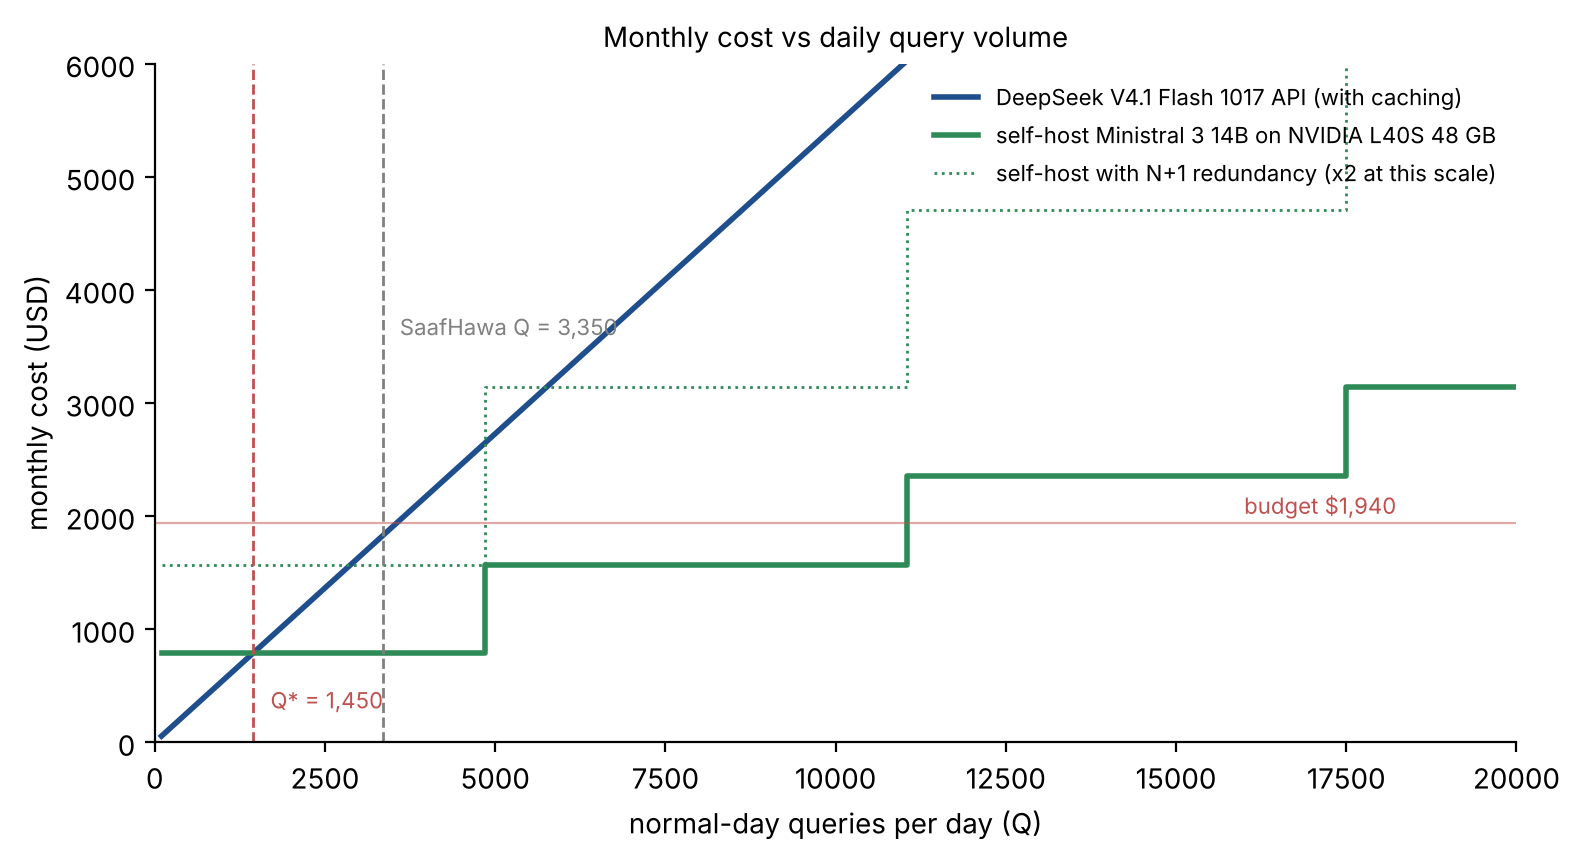

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(qs, api_curve, color="#1F4E8C", lw=2, label=f"{api_name} API (with caching)")
ax.step(qs, self_curve, where="post", color="#2E8B57", lw=2, label=f"self-host Ministral 3 14B on {GPU_NAME.split(' (')[0]}")
ax.step(qs, self_curve * 2, where="post", color="#2E8B57", lw=1, ls=":", label="self-host with N+1 redundancy (x2 at this scale)")
ax.set_xlim(0, 20000); ax.set_ylim(0, 6000)
ax.axvline(Q, color="gray", ls="--", lw=1); ax.text(Q + 250, 3600, f"SaafHawa Q = {Q:,}", fontsize=8, color="gray")
if Q_star:
    ax.axvline(Q_star, color="#C0504D", ls="--", lw=1); ax.text(Q_star + 250, 300, f"Q* = {Q_star:,}", fontsize=8, color="#C0504D")
ax.axhline(B, color="#C0504D", lw=0.8, alpha=0.5); ax.text(16000, B + 80, f"budget ${B:,}", fontsize=8, color="#C0504D")
ax.set_xlabel("normal-day queries per day (Q)"); ax.set_ylabel("monthly cost (USD)")
ax.legend(frameon=False, fontsize=8, loc="upper right"); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Monthly cost vs daily query volume", fontsize=10)
plt.tight_layout(); plt.savefig("q1_breakeven.png", dpi=200); plt.show()

In [23]:
results = dict(R=R, D=D, Q=Q, N=N, p=p, H=H, B=B, T=T, E_in=E_in, E_out=E_out, E_calls=E_calls, q_month=q_month,
               M_in=M_in, M_out=M_out, M_calls=M_calls, M_cacheable=M_cacheable, qpm=qpm, rpm_peak=rpm_peak,
               in_tpm=in_tpm, out_tpm=out_tpm, uncached_in_tpm=uncached_in_tpm,
               tool_delay=TOOL_DELAY, api_only=API_ONLY, per_gpu=per_gpu, kv_bytes=kv_bytes, seq_len=seq_len,
               gpus_now=gpus_needed(Q)[0], gpu_month=gpu_month, Q_star=Q_star, api_name=api_name, api_per_query=api_per_query,
               session=SESSION, prefill_peak=prefill_peak, no_cache_prefill=no_cache_prefill,
               peak_lambda=lam, mean_conc=mc, p99_conc=float(p99), be_rows=be_rows, Q_star_redundant=Q_star_redundant,
               haiku_peak_otpm=float(rl_df.set_index("model").loc["Claude Haiku 5.5", "peak output TPM"]))
json.dump(results, open("q1_results.json", "w"), indent=1, default=float)
cost.to_csv("q1_costs.csv", index=False); rl_df.to_csv("q1_rate_limits.csv", index=False); lat.to_csv("q1_latency.csv", index=False)
df.to_csv("q1_models.csv", index=False)
pd.DataFrame([(k, v[0], v[1], ACCESS) for k, v in SOURCES.items()], columns=["id", "source", "url", "accessed"]).to_csv("q1_sources.csv", index=False)
print("saved")

saved
